# Enhancer effects and guide efficiencies in K562
Estimate element effects for 94 candidate enhancers, two TSS controls and four non-targeting elements from the [Gasperini at-scale CRISPRi screen](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120861). The analysis retains 8,000 uniformly sampled cells, both guides per element and 256 response genes, including the PPP2R5A neighborhood. Work from `docs/tutorials/`.

## Design and cis candidates
The selected guide columns describe a subset of the perturbations carried by each cell. The original guide count, RNA library size and batch labels come from the full screen. The candidate map uses the original element and Ensembl identifiers.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import mudata
import numpy as np
import pandas as pd

source = Path("inputs/gasperini.h5mu")
run = Path("runs/gasperini")
run.mkdir(parents=True, exist_ok=True)
fitted = run / "fitted.h5mu"

In [2]:
with mudata.set_options(pull_on_update=False):
    screen = mudata.read_h5mu(source)
rna, guides = screen.mod["gene"], screen.mod["guide"]
mapping = guides.varm["guide_intended_target_pairs"]
elements = pd.Index(guides.uns["intended_targets"])
carriers = ((guides.X > 0) @ mapping) > 0
coverage = pd.Series(np.asarray(carriers.sum(axis=0)).ravel(), index=elements, name="cells")
print(f"{rna.n_obs:,} cells, {len(elements)} elements, {rna.n_vars} genes")
print(f"Median guides per cell in the original screen: {rna.obs.guide_count.median():g}")

full_map = pd.read_parquet("../../examples/manuscript/gasperini-cis-candidates.parquet")
cis = full_map.loc[full_map.element.isin(elements) & full_map.gene.isin(rna.var_names)]
cis_path = run / "cis_candidates.parquet"
if cis_path.exists():
    if not pd.read_parquet(cis_path).equals(cis.reset_index(drop=True)):
        raise ValueError("Existing fit directory has a different cis family. Choose a fresh run directory.")
else:
    cis.to_parquet(cis_path, index=False)
print(f"{len(cis)} cis candidates across {cis.element.nunique()} enhancers")
coverage.describe().round(1)

8,000 cells, 100 elements, 256 genes
Median guides per cell in the original screen: 29
387 cis candidates across 94 enhancers


count    100.0
mean      34.0
std       13.2
min        8.0
25%       25.0
50%       31.5
75%       40.2
max       80.0
Name: cells, dtype: float64

## Fit the high-MOI screen
Use the all-cells propensity test and relative guide model. All 8,000 cells enter the baseline with the original whole-library size, RNA depth, mitochondrial fraction and preparation batch. The cis map defines a pooled BH family. The fit also reports screen-wide and within-element adjustments over this subset.

In [3]:
flags = f"""
--modality-key gene --perturbation-modality-key guide
--perturbation-element-varm-key guide_intended_target_pairs --perturbation-element-names-uns-key intended_targets
--library-size-key total_umis --continuous-covariates total_umis percent_mito --batch-covariate prep_batch
--guide-effect-strategy relative --crt-pool all-cells --cis-pairs {shlex.quote(str(run / "cis_candidates.parquet"))}
--size-factor-mode observed --likelihood negbin --prior normal
--num-steps-control 500 --num-steps-betas 500 --minibatch-size-control 512 --minibatch-size-betas 512
--step-size 0.01 --max-control-cells 8000 --crt --crt-mechanism propensity
--crt-tail-families saddlepoint --crt-saddlepoint-only --crt-two-sided equal-tail --crt-polish-baseline
--crt-gene-chunk-size 32 --crt-max-gather-gib 1 --crt-seed 0 --save-model-params --device cpu --no-progress-bar
"""
args = ["--input", str(source), "--out-dir", str(run), *shlex.split(flags)]
receipt = run / "teaching_command.json"
with source.open("rb") as handle:
    input_hash = hashlib.file_digest(handle, "sha256").hexdigest()
settings = {"args": args, "input_sha256": input_hash}
if fitted.exists():
    if not receipt.exists() or json.loads(receipt.read_text()) != settings:
        raise ValueError("Existing fit uses different settings. Choose a fresh run directory.")
    print(f"Using {fitted}")
else:
    # Keep the complete CLI transcript alongside the result.
    with (run / "cli.log").open("w") as log:
        result = subprocess.run([sys.executable, "-m", "perturbo.cli", *args], stdout=log, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError((run / "cli.log").read_text()[-4000:])
    receipt.write_text(json.dumps(settings, indent=2))
    print(f"Saved {fitted}")

Using runs/gasperini/fitted.h5mu


## Compare cis effects and inspect individual guides
The plot ranks the ten lowest cis q-values, with raw p-value breaking ties. Each point is an element–gene pair. The table below reports the two guide multipliers for the prespecified LMO2 enhancer.

2 cis discoveries among 387 finite tests


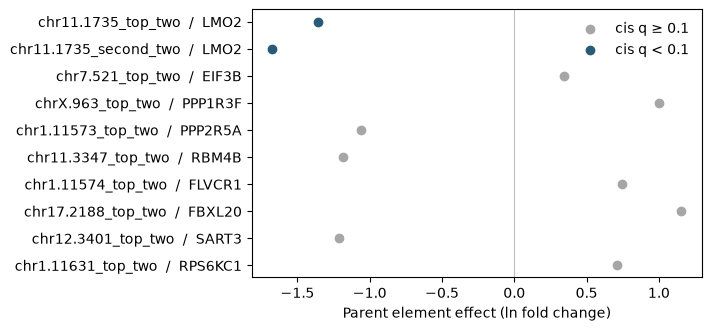

In [4]:
with mudata.set_options(pull_on_update=False):
    pt = mudata.read_h5mu(fitted).uns["_perturbo"]
effects = pt["effects"]
local = effects.loc[effects.q_cis.notna()].copy()
local["symbol"] = local.gene.map(rna.var.symbol.to_dict())
top = local.sort_values(["q_cis", "p_value", "element", "gene"]).head(10).iloc[::-1]
print(f"{local.q_cis.lt(0.1).sum()} cis discoveries among {len(local)} finite tests")

fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
ax.axvline(0, color="0.75", lw=0.8)
for passed, color in [(False, "0.65"), (True, "#285b77")]:
    mask = top.q_cis.lt(0.1).eq(passed)
    ax.scatter(top.posterior_mean[mask], np.flatnonzero(mask), color=color,
               label="cis q < 0.1" if passed else "cis q ≥ 0.1")
ax.set(yticks=range(len(top)), yticklabels=top.element.astype(str) + "  /  " + top.symbol.astype(str),
       xlabel="Parent element effect (ln fold change)")
ax.legend(frameon=False)
plt.show()

In [5]:
lmo2 = rna.var_names[rna.var.symbol.eq("LMO2")].item()
efficiency = pt["efficiency"]
efficiency.loc[efficiency.element.eq("chr11.1735_top_two") & efficiency.gene.eq(lmo2),
               ["element", "guide", "gene", "guide_relative_efficiency_mean",
                "guide_relative_efficiency_scale"]]

,element,guide,gene,guide_relative_efficiency_mean,guide_relative_efficiency_scale
7834,chr11.1735_top_two,GAAATGTTCTACCAGCTACA,ENSG00000135363,0.843154,0.119251
8090,chr11.1735_top_two,GCTGTGGCTCAGCCTCCCCA,ENSG00000135363,0.898867,0.089683


The [cis power tutorial](gasperini_power.ipynb) starts from this fitted object. The [full-screen command](https://github.com/pinellolab/PerTurbo/blob/542a832346622cf3f50bba4c1327e969fc3b8229/examples/manuscript/README.md) documents the manuscript input, fit schedule and complete cis family.